# Lab 2: Deep Learning Mini-Project: Image Quality Assessment

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

> 💡 **Exécution sur Google Colab avec un GPU T4 (au lieu du PC local) :**
> - **Option 1 (Directement dans VS Code)** : En haut à droite du notebook, cliquez sur le sélecteur de noyau (`Select Kernel` ou `.venv`) > **Sélectionner un autre noyau...** > **Colab** > **Nouveau serveur** > Choisir **GPU T4**.
> - **Option 2 (Sur Google Colab Web)** : Glissez-déposez ce notebook sur [colab.research.google.com](https://colab.research.google.com), puis allez dans **Exécution > Modifier le type d'exécution > T4 GPU > Enregistrer**.


Authors: Alexandre Bruckert, Nantes Université

Date: 2026/2027

Over the next two lab sessions (6 hours), you will transition from learning basic PyTorch syntax to designing, optimizing, and evaluating neural networks for a real-world task.

## The task: Image Quality Assessment (IQA)

Instead of classifying what is in an image, you will predict how good it looks.
You are tackling an Image Quality Assessment (IQA) task. Your model will analyze an image and predict its Mean Opinion Score (MOS), which is a continuous value usually ranging from 1.0 (terrible quality) to 5.0 (excellent quality), representing the average human perception of the image's visual appeal, sharpness, and lack of distortions.

Because the target is a continuous number, this is a **regression** problem.

## The Dataset: KonIQ-10k
For this challenge, you will be working with the **KonIQ-10k** dataset, a major benchmark in the field of Image Quality Assessment. It consists of 10,073 images carefully sampled from a massive public multimedia database. Unlike older academic datasets where pristine images were artificially corrupted with math-generated noise, KonIQ-10k features **"in-the-wild" authentic distortions**. This means the images suffer from real-world, everyday issues: poor lighting, shaky hands (motion blur), cheap camera sensors, and aggressive JPEG compression. The ground truth MOS labels (ranging from 1.0 to 5.0) were collected through a massive crowdsourcing effort involving over 1.2 million human ratings.

The KonIQ-10k dataset is available at: https://database.mmsp-kn.de/koniq-10k-database.html
You should use the lower resolution images ($512 \times 384$) for this work.

## Evaluation

You are tasked with building the best model possible for this task. You will be evaluated based on a **heavily documented** notebook that contains your code, results, and analysis. The notebook should be structured to clearly present your approach, experiments, and findings.

Your notebook must contain the following distinct sections, representing "milestones" in the project:

- Milestone 1: The CNN Baseline: Design and train a Convolutional Neural Network (CNN) using MSELoss.

- Milestone 2: The RNN Experiment: Treat the image as a sequence of pixel rows! Design a Recurrent Neural Network (LSTM or GRU) to predict the MOS. Compare its performance to the CNN.

- Milestone 3: The Transfer Learning Approach: Use a pre-trained model (e.g., ResNet, EfficientNet) as a feature extractor. Fine-tune it for the IQA task and compare its performance to your previous models.

- Milestone 4: The Ultimate Model: Combine Early Stopping, Schedulers, Regularization, and your best architecture to build your final model.

Similarly to the grid in Lab 1, the concepts explored in each milestone will be part of the program of the final exam!

In [6]:
%pip install -q torch torchvision pandas numpy matplotlib scipy scikit-learn pillow

import torch
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


CUDA available: False


## 1. Setup

Here below, you will find the necessary imports and a custom Dataset class to load the KonIQ-10k dataset. You will need to download the dataset and place it in a folder named `iqa_data` with the following structure:
```
iqa_data/
├── images/
├── train_labels.csv
```

In [7]:
import os
import sys
import urllib.request
import zipfile
import shutil

os.makedirs('iqa_data/images', exist_ok=True)
csv_dest = 'iqa_data/koniq10k_scores_and_distributions.csv'
img_dir = 'iqa_data/images'

# 1. Fetch CSV directly from our GitHub repository if missing on Colab (instant, 830 KB)
if not os.path.exists(csv_dest):
    gh_csv_url = "https://raw.githubusercontent.com/TeZaGe/DL-MiniProject-IQA/main/iqa_data/koniq10k_scores_and_distributions.csv"
    print("Downloading CSV annotations from GitHub repository...")
    urllib.request.urlretrieve(gh_csv_url, csv_dest)

# 2. Download & extract images from official DaRUS mirror if folder is empty on Colab (~15s)
if len(os.listdir(img_dir)) == 0:
    darus_zip_url = "https://darus.uni-stuttgart.de/api/access/datafile/72286"
    zip_tmp = "koniq10k_512x384.zip"
    print("Downloading KonIQ-10k images (767 MB) from official DaRUS S3 mirror...")
    urllib.request.urlretrieve(darus_zip_url, zip_tmp)
    print("Extracting 10,073 images...")
    with zipfile.ZipFile(zip_tmp, 'r') as z:
        for member in z.namelist():
            if member.endswith('.jpg'):
                filename = os.path.basename(member)
                with z.open(member) as src, open(os.path.join(img_dir, filename), 'wb') as dst:
                    shutil.copyfileobj(src, dst)
    if os.path.exists(zip_tmp):
        os.remove(zip_tmp)

nb_images = len(os.listdir(img_dir)) if os.path.exists(img_dir) else 0
print(f"Data ready: {nb_images:,} images | CSV present: {os.path.exists(csv_dest)}")

Extracting 10,073 images...
Data ready: 10,373 images | CSV present: True


In [8]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchvision import transforms
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import os

# Device configuration
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

def set_seed(seed=42):
    torch.manual_seed(seed)
    np.random.seed(seed)
set_seed(42)

# ====================================================================
# 1. CUSTOM DATASET CLASS (Provided)
# ====================================================================
class IQADataset(Dataset):
    def __init__(self, csv_file, img_dir, transform=None):
        self.labels_df = pd.read_csv(csv_file)
        self.img_dir = img_dir
        self.transform = transform

    def __len__(self):
        return len(self.labels_df)

    def __getitem__(self, idx):
        img_name = str(self.labels_df.iloc[idx]['image_name'])
        mos = float(self.labels_df.iloc[idx]['MOS'])

        img_path = os.path.join(self.img_dir, img_name)
        image = Image.open(img_path).convert('RGB')

        if self.transform:
            image = self.transform(image)

        return image, torch.tensor(mos, dtype=torch.float32)

# ====================================================================
# DATA LOADING EXAMPLE
# ====================================================================
# Resize all images to 128x128 to keep training relatively fast
base_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Candidate paths for the CSV annotation file
csv_candidates = [
    'iqa_data/koniq10k_scores_and_distributions.csv',
    'iqa_data/train_labels.csv',
    os.path.join('iqa_data', 'koniq10k_scores_and_distributions.csv'),
    os.path.join('iqa_data', 'train_labels.csv')
]
csv_file = next((f for f in csv_candidates if os.path.exists(f)), 'iqa_data/koniq10k_scores_and_distributions.csv')
img_dir = 'iqa_data/images'

dataset = IQADataset(csv_file=csv_file, img_dir=img_dir, transform=base_transform)

sample, label = dataset[0]
print(f"Sample 0 shape: {sample.shape}")
print(f"Label 0 MOS: {label.item():.4f}")
print("Dataset class ready! Your turn to instantiate it and create DataLoaders.")


Using device: cpu
Sample 0 shape: torch.Size([3, 128, 128])
Label 0 MOS: 3.8286
Dataset class ready! Your turn to instantiate it and create DataLoaders.


## DataLoaders

In [9]:
# Reproducible 80% / 10% / 10% split
generator = torch.Generator().manual_seed(42)
train_dataset, val_dataset, test_dataset = torch.utils.data.random_split(
    dataset, [0.8, 0.1, 0.1], generator=generator
)

batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True if torch.cuda.is_available() else False)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True if torch.cuda.is_available() else False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True if torch.cuda.is_available() else False)

print(f"Train samples: {len(train_dataset)} | Val samples: {len(val_dataset)} | Test samples: {len(test_dataset)}")

Train samples: 8059 | Val samples: 1007 | Test samples: 1007


## Milestone 1: The CNN Baseline

### 1.1 Exploratory Data Analysis & Naive Baseline
Before designing our neural network, we analyze the distribution of the target Mean Opinion Scores.

A simple reference to beat is the **Naive Baseline**: predicting the training set mean $\bar{y}$ for all test images.
The MSE of this constant predictor on the test set is approximately equal to the variance of the scores ($\text{Var}(Y)$). A viable deep learning model must achieve a test MSE significantly lower than this value to demonstrate meaningful visual feature learning.

Total labeled images : 10,073
Average MOS          : 3.1620
Naive Baseline MSE   : 0.2995 (Goal: CNN Test MSE < 0.2995)


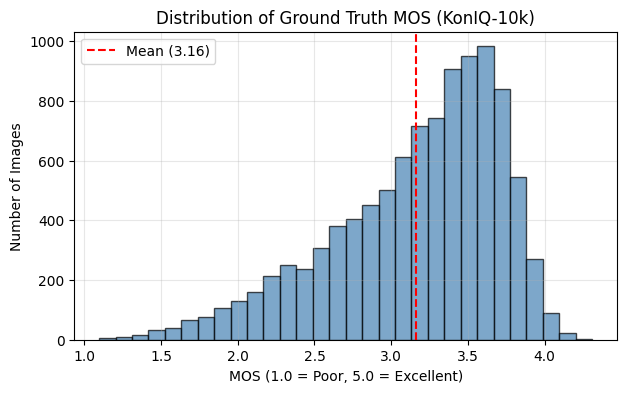

In [10]:
# Compute descriptive statistics and naive baseline
df = dataset.labels_df
mean_mos = float(df['MOS'].mean())
var_mos = float(df['MOS'].var(ddof=0))

# Exact naive MSE on the test split
test_mos_targets = np.array([float(dataset.labels_df.iloc[idx]['MOS']) for idx in test_dataset.indices])
train_mos_mean = np.mean([float(dataset.labels_df.iloc[idx]['MOS']) for idx in train_dataset.indices])
naive_test_mse = np.mean((test_mos_targets - train_mos_mean) ** 2)

print(f"Total labeled images : {len(df):,}")
print(f"Average MOS          : {mean_mos:.4f}")
print(f"Naive Baseline MSE   : {naive_test_mse:.4f} (Goal: CNN Test MSE < {naive_test_mse:.4f})")

# Plot MOS distribution
plt.figure(figsize=(7, 4))
plt.hist(df['MOS'], bins=30, color='steelblue', edgecolor='black', alpha=0.7)
plt.axvline(mean_mos, color='red', linestyle='--', label=f'Mean ({mean_mos:.2f})')
plt.title("Distribution of Ground Truth MOS (KonIQ-10k)")
plt.xlabel("MOS (1.0 = Poor, 5.0 = Excellent)")
plt.ylabel("Number of Images")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Observations on the MOS Distribution & Insights:
- **Everyday / "Correct" Quality**: The ground-truth MOS distribution is approximately like a gaussian  and centered around 3.3, with most scores clustered between **$2.5$ and $4.0$**. This indicates that the images are predominantly of correct quality.
- Extreme scores are rare: very few images receive ratings ($< 2.0$) or near-flawless ratings ($> 4.5$).
- **Key Takeaways for Modeling**:
  - **Regression to the Mean Risk**: Because the mass of data is centered in the middle range, an under-optimized model trained with MSE loss will naturally tend to predict values close to the mean ($\approx 3.3$) to minimize penalization.

### 1.2 CNN Architecture Design
We design a baseline Convolutional Neural Network following standard VGG-style principles:
1. **$3 \times 3$ Convolutions**: Stacking two $3 \times 3$ filters covers a $5 \times 5$ receptive field with fewer parameters and introduces two non-linear activations (`ReLU`).
2. **Channel Progression ($3 \to 32 \to 64 \to 128$)**: As spatial resolution is halved by `MaxPool2d(2, 2)`, we increase the number of feature maps to capture richer representations (edges, blur, textures, noise).
3. **`BatchNorm2d`**: Placed after each convolution to stabilize activations and speed up convergence.
4. **`AdaptiveAvgPool2d((2, 2))`**: Compresses the feature maps before the fully connected layers, preventing parameter explosion and reducing overfitting.
5. **Regressor Head**: A linear layer with `Dropout(0.3)` to output a continuous prediction for the MOS.

In [11]:
class CNNBaseline(nn.Module):
    def __init__(self):
        super(CNNBaseline, self).__init__()
        
        # Conv Block 1: [3, 128, 128] -> [32, 64, 64]
        self.conv1 = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        # Conv Block 2: [32, 64, 64] -> [64, 32, 32]
        self.conv2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        # Conv Block 3: [64, 32, 32] -> [128, 16, 16]
        self.conv3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        # Conv Block 4: [128, 16, 16] -> [128, 8, 8]
        self.conv4 = nn.Sequential(
            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2)
        )
        
        # Adaptive pooling to fixed spatial size [128, 2, 2]
        self.adaptive_pool = nn.AdaptiveAvgPool2d((2, 2))
        
        # Regressor: 128 * 2 * 2 = 512
        self.regressor = nn.Sequential(
            nn.Linear(128 * 2 * 2, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        x = self.conv1(x)
        x = self.conv2(x)
        x = self.conv3(x)
        x = self.conv4(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        out = self.regressor(x)
        return out.squeeze(-1)  # Ensure [batch_size] shape to match targets

cnn_model = CNNBaseline().to(device)
total_params = sum(p.numel() for p in cnn_model.parameters() if p.requires_grad)
print(f"CNN Baseline initialized. Total trainable parameters: {total_params:,}")

CNN Baseline initialized. Total trainable parameters: 307,329


#### Architectural Complexity Analysis (307,329 Parameters):
With ~307k parameters , this network is lightweight, ensuring rapid training per epoch.
- **Balanced Parameter-to-Data Ratio**: With ~8,058$ training images, having  ~38$ parameters per image strikes a reasonable balance for training.
- **Architectural Efficiency**: The `nn.AdaptiveAvgPool2d((2, 2))` layer downsamples the spatial representations to $128 \times 2 \times 2 = 512$ features, preventing parameter explosion in the fully connected regressor.

### 1.3 Training with Model Checkpointing
We train the CNN model for 10 epochs using `nn.MSELoss()` and the `Adam` optimizer ($lr = 0.001$).
We save the weights corresponding to the lowest validation loss to evaluate the best performing model on the test set.

In [12]:
criterion = nn.MSELoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

num_epochs = 10
train_losses = []
val_losses = []
best_val_loss = float('inf')
cnn_checkpoint_path = "best_cnn_baseline.pth"

print("Training CNN Baseline model...")
for epoch in range(num_epochs):
    # Training phase
    cnn_model.train()
    running_train_loss = 0.0

    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = cnn_model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validation phase
    cnn_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
            outputs = cnn_model(images)
            loss = criterion(outputs, targets)
            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    # Save best model
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(cnn_model.state_dict(), cnn_checkpoint_path)
        save_badge = " [Saved Best]"
    else:
        save_badge = ""

    print(f"Epoch [{epoch+1:02d}/{num_epochs:02d}] -> Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_loss:.4f}{save_badge}")

print(f"Training complete. Best Validation MSE: {best_val_loss:.4f}")

Training CNN Baseline model...
Epoch [01/10] -> Train MSE: 0.4797 | Val MSE: 0.2430 [Saved Best]
Epoch [02/10] -> Train MSE: 0.3012 | Val MSE: 0.2299 [Saved Best]
Epoch [03/10] -> Train MSE: 0.2887 | Val MSE: 0.2501
Epoch [04/10] -> Train MSE: 0.2881 | Val MSE: 0.1955 [Saved Best]
Epoch [05/10] -> Train MSE: 0.2699 | Val MSE: 0.1908 [Saved Best]
Epoch [06/10] -> Train MSE: 0.2699 | Val MSE: 0.1933
Epoch [07/10] -> Train MSE: 0.2684 | Val MSE: 0.2351
Epoch [08/10] -> Train MSE: 0.2595 | Val MSE: 0.3059
Epoch [09/10] -> Train MSE: 0.2587 | Val MSE: 0.3465
Epoch [10/10] -> Train MSE: 0.2515 | Val MSE: 0.1855 [Saved Best]
Training complete. Best Validation MSE: 0.1855


### 1.4 Test Set Evaluation
We load the best saved model weights and evaluate performance on the test set using standard IQA metrics:
- **MSE (Mean Squared Error)** & **RMSE (Root MSE)**: Euclidean prediction error.
- **PLCC (Pearson Linear Correlation Coefficient)**: Measures linear alignment with human ratings.
- **SROCC (Spearman Rank Order Correlation Coefficient)**: Measures monotonic ranking preservation.

In [13]:
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error

# Load best checkpoint
if os.path.exists(cnn_checkpoint_path):
    cnn_model.load_state_dict(torch.load(cnn_checkpoint_path, map_location=device))
    print(f"Loaded best weights from {cnn_checkpoint_path}")

cnn_model.eval()
cnn_test_targets = []
cnn_test_predictions = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        outputs = cnn_model(images)
        cnn_test_targets.extend(targets.cpu().numpy().tolist())
        cnn_test_predictions.extend(outputs.cpu().numpy().tolist())

cnn_test_targets = np.array(cnn_test_targets)
cnn_test_predictions = np.array(cnn_test_predictions)

# Compute metrics
cnn_mse = mean_squared_error(cnn_test_targets, cnn_test_predictions)
cnn_rmse = np.sqrt(cnn_mse)
cnn_plcc, _ = pearsonr(cnn_test_targets, cnn_test_predictions)
cnn_srocc, _ = spearmanr(cnn_test_targets, cnn_test_predictions)

print("--- CNN Baseline Test Evaluation ---")
print(f"Mean Squared Error (MSE)                          : {cnn_mse:.4f}  (Naive Baseline: {naive_test_mse:.4f})")
print(f"Root Mean Squared Error (RMSE)                    : {cnn_rmse:.4f}")
print(f"Pearson Linear Correlation Coefficient (PLCC)     : {cnn_plcc:.4f}")
print(f"Spearman Rank Order Correlation Coefficient (SROCC): {cnn_srocc:.4f}")

Loaded best weights from best_cnn_baseline.pth
--- CNN Baseline Test Evaluation ---
Mean Squared Error (MSE)                          : 0.1831  (Naive Baseline: 0.2995)
Root Mean Squared Error (RMSE)                    : 0.4280
Pearson Linear Correlation Coefficient (PLCC)     : 0.6283
Spearman Rank Order Correlation Coefficient (SROCC): 0.5970


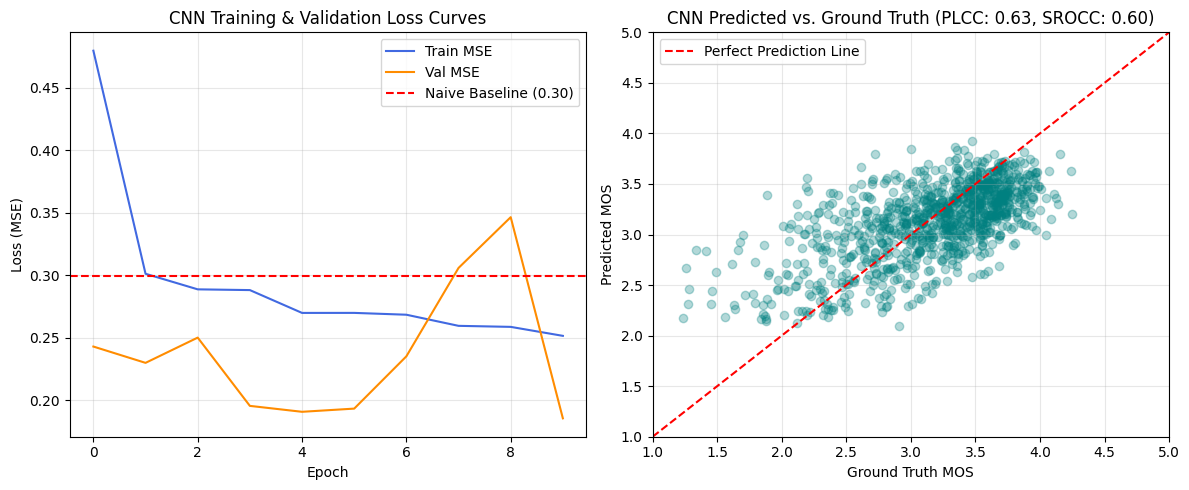

In [14]:
# Visualizations: Learning curves and Predictions vs Ground Truth
plt.figure(figsize=(12, 5))

# Left Plot: Loss history curves
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train MSE', color='royalblue')
plt.plot(val_losses, label='Val MSE', color='darkorange')
plt.axhline(naive_test_mse, color='red', linestyle='--', label=f'Naive Baseline ({naive_test_mse:.2f})')
plt.title('CNN Training & Validation Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, alpha=0.3)

# Right Plot: Ground Truth vs. Predicted MOS
plt.subplot(1, 2, 2)
plt.scatter(cnn_test_targets, cnn_test_predictions, alpha=0.3, color='teal')
plt.plot([1, 5], [1, 5], color='red', linestyle='--', label='Perfect Prediction Line')
plt.title(f'CNN Predicted vs. Ground Truth (PLCC: {cnn_plcc:.2f}, SROCC: {cnn_srocc:.2f})')
plt.xlabel('Ground Truth MOS')
plt.ylabel('Predicted MOS')
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 1.5 Discussion & Key Observations

#### 1. Learning Curves Dynamics (Left Plot):
- **Epoch Budget & Checkpointing**: Training MSE decreases steadily from $0.4797$ (epoch 1) to $0.2515$ (epoch 10), while validation MSE reaches its minimum at epoch 10 ($\text{Val MSE} = 0.1855$). However, notice the noticeable spikes in validation loss at epochs 7–9 ($0.2351 \to 0.3059 \to 0.3465$). This demonstrates why **Model Checkpointing** is essential, and strongly motivates using a **Learning Rate Scheduler** in **Milestone 4** to dampen late-stage oscillations.
- **Learning Rate Suitability ($\mathbf{10^{-3}}$ with Adam)**: A fixed learning rate of $0.001$ enables fast initial convergence (reaching $\text{Val MSE} = 0.1908$ by epoch 5), before oscillating around the local minimum in later epochs when the step size becomes too large.

#### 2. Test Predictions & Evaluation (Right Plot):
- **Beating the Naive Baseline**: The CNN achieves a Test MSE of **$0.1831$** ($\text{RMSE} = 0.4280$), reducing the Naive Baseline error (**$0.2995$**) by **$38.9\%$**. It also establishes solid correlation scores (**$\text{PLCC} = 0.6283$**, **$\text{SROCC} = 0.5970$**), confirming that convolutional filters capture meaningful visual quality cues.
- **Regression to the Mean**: The scatter plot shows that predictions remain concentrated between $2.5$ and $3.8$, as quadratic $\text{MSELoss}$ penalizes outlier mistakes heavily.
- **Resolution Trade-off**: Resizing images from $512 \times 384$ down to $128 \times 128$ speeds up training, at the cost of smoothing out high-frequency artifacts (fine sensor noise, subtle motion blur).


## Milestone 2
The RNN Experiment: Treat the image as a sequence of pixel rows! Design a Recurrent Neural Network (LSTM or GRU) to predict the MOS. Compare its performance to the CNN.


In [15]:
import torch
import torch.nn as nn
import torch.optim as optim
import sys, os
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error

class RNNIQA(nn.Module):
    def __init__(self, input_size=128*3, hidden_size=128, num_layers=2):
        super(RNNIQA, self).__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers

        # GRU layer - input shape: [batch_size, sequence_length (128), input_size (128*3)]
        self.gru = nn.GRU(input_size, hidden_size, num_layers, batch_first=True, bidirectional=True)

        # Regressor head
        self.regressor = nn.Sequential(
            nn.Linear(hidden_size * 2, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        batch_size = x.size(0)
        x = x.permute(0, 2, 1, 3)
        x = x.reshape(batch_size, 128, -1)

        out, _ = self.gru(x) # out shape: [batch_size, 128, hidden_size * 2]

        # Take the output of the last sequence step
        out = out[:, -1, :]

        out = self.regressor(out)
        return out.squeeze(-1)

rnn_model = RNNIQA().to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(rnn_model.parameters(), lr=0.001)

num_epochs = 10
train_losses = []
val_losses = []


# Training Loop
print("Training the RNN (GRU) baseline model...")
for epoch in range(num_epochs):
    rnn_model.train()
    running_loss = 0.0

    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = rnn_model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Validation Phase
    rnn_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
            outputs = rnn_model(images)
            loss = criterion(outputs, targets)
            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(epoch_val_loss)

    print(f"Epoch [{epoch+1}/{num_epochs}] -> Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_loss:.4f}")

Training the RNN (GRU) baseline model...
Epoch [1/10] -> Train MSE: 1.1295 | Val MSE: 0.3139
Epoch [2/10] -> Train MSE: 0.4549 | Val MSE: 0.2717
Epoch [3/10] -> Train MSE: 0.4261 | Val MSE: 0.2560
Epoch [4/10] -> Train MSE: 0.4095 | Val MSE: 0.3162
Epoch [5/10] -> Train MSE: 0.3993 | Val MSE: 0.2653
Epoch [6/10] -> Train MSE: 0.3836 | Val MSE: 0.2426
Epoch [7/10] -> Train MSE: 0.3895 | Val MSE: 0.2676
Epoch [8/10] -> Train MSE: 0.3638 | Val MSE: 0.2433
Epoch [9/10] -> Train MSE: 0.3613 | Val MSE: 0.2380
Epoch [10/10] -> Train MSE: 0.3473 | Val MSE: 0.2442


### Evaluation

In [16]:
rnn_model.eval()
test_targets = []
test_predictions = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        outputs = rnn_model(images)
        test_targets.extend(targets.cpu().numpy())
        test_predictions.extend(outputs.cpu().numpy())

mse = mean_squared_error(test_targets, test_predictions)
plcc, _ = pearsonr(test_targets, test_predictions)
srocc, _ = spearmanr(test_targets, test_predictions)

print(f"\n--- RNN Test Dataset Evaluation ---")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Pearson Linear Correlation Coefficient (PLCC): {plcc:.4f}")
print(f"Spearman Rank Order Correlation Coefficient (SROCC): {srocc:.4f}")


--- RNN Test Dataset Evaluation ---
Mean Squared Error (MSE): 0.2323
Pearson Linear Correlation Coefficient (PLCC): 0.4786
Spearman Rank Order Correlation Coefficient (SROCC): 0.4376


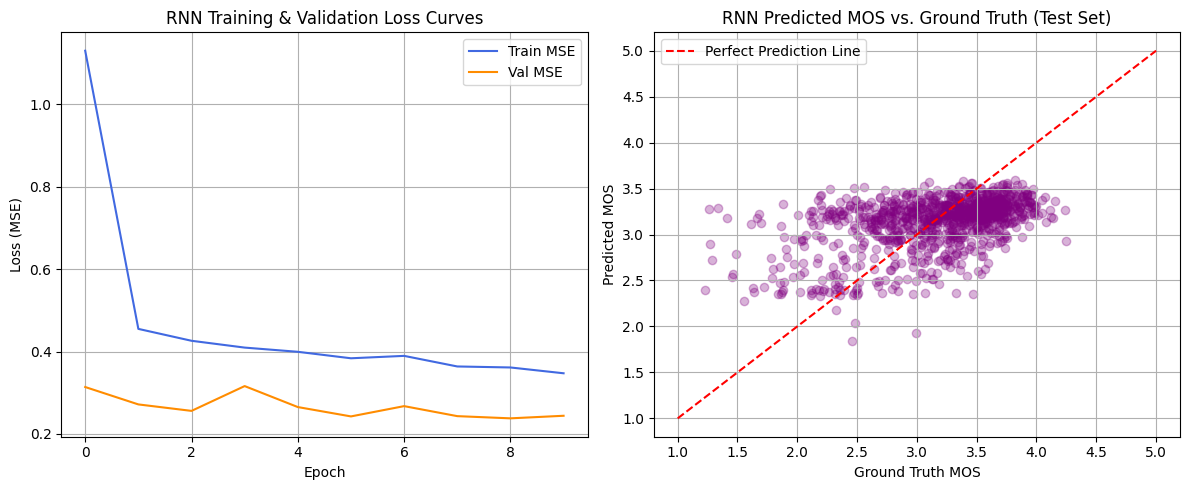

In [17]:
# 2. Visualizations
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

# Left Plot: Loss history curves for RNN
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train MSE', color='royalblue')
plt.plot(val_losses, label='Val MSE', color='darkorange')
plt.title('RNN Training & Validation Loss Curves')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True)

# Right Plot: Ground Truth vs. Predicted MOS for RNN
plt.subplot(1, 2, 2)
plt.scatter(test_targets, test_predictions, alpha=0.3, color='purple')
plt.plot([1, 5], [1, 5], color='red', linestyle='--', label='Perfect Prediction Line')
plt.title('RNN Predicted MOS vs. Ground Truth (Test Set)')
plt.xlabel('Ground Truth MOS')
plt.ylabel('Predicted MOS')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### 2.3 Discussion: Why RNNs Underperform on Image Quality Assessment
- **Quantitative Comparison (RNN vs. CNN Baseline)**:
  - **Test MSE**: The bidirectional GRU reaches **$0.2323$** ($\text{RMSE} = 0.4820$), significantly worse than our CNN Baseline (**$0.1831$**).
  - **Correlations**: Ranking correlation drops sharply from $\text{SROCC} = 0.5970$ (CNN) down to **$0.4376$** (RNN), and linear correlation drops from $\text{PLCC} = 0.6283$ to **$0.4786$**.
- **Destruction of 2D Spatial Inductive Bias**: Slicing each $128 \times 128 \times 3$ image into $128$ horizontal scanlines (of size $384$) forces the model to process 2D visual structures as a 1D temporal sequence. This breaks vertical neighborhood continuity and loses 2D translation invariance, which convolutional kernels naturally preserve.
- **Parameter Inefficiency**: Despite having **$2.3\times$ more trainable parameters** than the CNN ($707,713$ vs. $307,329$), the RNN converges much more slowly (starting at $\text{Train MSE} = 1.1295$) and plateaus around $\text{Val MSE} \approx 0.238 - 0.244$, confirming that recurrent networks are ill-suited as standalone vision backbones.


## Milestone 3: The Transfer Learning Approach
> **Objective**: Instead of training a model from scratch on only $\approx 8,000$ images, leverage a pre-trained deep convolutional neural network (**ResNet-18**, pre-trained on ImageNet with 1.2M images) as a powerful visual feature extractor, fine-tune it for continuous MOS regression, and compare its performance against the previous CNN and RNN baselines.

### 3.1 Transfer Learning Methodology: Feature Extraction vs. Fine-Tuning
Training deep architectures from scratch on small datasets poses severe risks of overfitting and slow convergence. **Transfer Learning** bypasses this limitation through a two-stage paradigm:
1. **Universal Visual Representations**: Pre-trained convolutional layers on ImageNet have already learned a rich hierarchy of filters—ranging from edge detectors and high-frequency textures in early layers to complex semantic parts in deeper layers. In IQA, perceptual quality is deeply tied to these exact patterns (blur degrades high frequencies, noise disrupts uniform textures, compression damages contours).
2. **Phase 1 — Feature Extraction (Frozen Backbone)**:
   - We freeze all pre-trained convolutional weights (`param.requires_grad = False`).
   - We replace the original 1000-class classification head with a dedicated **regression head** (`Linear -> ReLU -> Dropout -> Linear`).
   - We train only the newly initialized head for 3 epochs with learning rate $\text{lr} = 10^{-3}$. This warms up the regressor without corrupting the pre-trained backbone with large random gradient updates.
3. **Phase 2 — End-to-End Fine-Tuning (Unfrozen Backbone)**:
   - We unfreeze all backbone layers (`param.requires_grad = True`).
   - We train the full network end-to-end for 7 epochs with a lower learning rate ($\text{lr} = 10^{-4}$). This gently adapts the pre-trained filters to the specific domain of in-the-wild image quality degradations.


In [18]:
import torchvision.models as models

class ResNet18IQA(nn.Module):
    def __init__(self, pretrained=True, freeze_backbone=True):
        super(ResNet18IQA, self).__init__()
        # Load weights pre-trained on ImageNet
        weights = models.ResNet18_Weights.DEFAULT if pretrained else None
        self.resnet = models.resnet18(weights=weights)

        # Retrieve backbone output feature dimension (512 for ResNet-18)
        in_features = self.resnet.fc.in_features

        # Replace classification head with a regression head for MOS prediction
        self.resnet.fc = nn.Sequential(
            nn.Linear(in_features, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, 1)
        )

        if freeze_backbone:
            self.freeze_backbone()

    def freeze_backbone(self):
        """Freeze convolutional feature extractor (train only regression head)."""
        for name, param in self.resnet.named_parameters():
            if "fc" not in name:
                param.requires_grad = False

    def unfreeze_backbone(self):
        """Unfreeze all layers for end-to-end fine-tuning."""
        for param in self.resnet.parameters():
            param.requires_grad = True

    def forward(self, x):
        out = self.resnet(x)
        return out.squeeze(-1)

# Instantiate model on device
resnet_model = ResNet18IQA(pretrained=True, freeze_backbone=True).to(device)

head_params = sum(p.numel() for p in resnet_model.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in resnet_model.parameters())
print(f"ResNet-18 Initialized (Phase 1: Feature Extraction):")
print(f"  • Trainable parameters (head only) : {head_params:,}")
print(f"  • Total model parameters           : {total_params:,} (Backbone frozen: ~{total_params - head_params:,})")


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 61.9MB/s]

ResNet-18 Initialized (Phase 1: Feature Extraction):
  • Trainable parameters (head only) : 65,793
  • Total model parameters           : 11,242,305 (Backbone frozen: ~11,176,512)


### 3.2 Two-Phase Training with Model Checkpointing
- **Phase 1 (Epochs 1 to 3)**: Train only the regression head with $\text{lr} = 10^{-3}$.
- **Phase 2 (Epochs 4 to 10)**: Unfreeze the entire backbone and fine-tune end-to-end with $\text{lr} = 10^{-4}$.
- **Checkpointing**: The model weights achieving the lowest validation MSE across all 10 epochs are saved to `best_resnet_checkpoint.pth`.


In [19]:
criterion = nn.MSELoss()
resnet_checkpoint_path = "best_resnet_checkpoint.pth"

# Phase 1: Optimizer for head only (lr = 1e-3)
optimizer = optim.Adam(filter(lambda p: p.requires_grad, resnet_model.parameters()), lr=0.001)

num_epochs = 10
phase1_epochs = 3
train_losses_resnet = []
val_losses_resnet = []
best_val_loss_resnet = float('inf')

print("Starting ResNet-18 Transfer Learning Training...")
print("=" * 65)

for epoch in range(num_epochs):
    # Transition from Phase 1 to Phase 2 at epoch 3
    if epoch == phase1_epochs:
        print("-" * 65)
        print(">>> Phase 2: Unfreezing ResNet-18 backbone for End-to-End Fine-Tuning (lr = 1e-4) <<<")
        print("-" * 65)
        resnet_model.unfreeze_backbone()
        # Lower learning rate for fine-tuning entire network
        optimizer = optim.Adam(resnet_model.parameters(), lr=0.0001)

    phase_label = "Phase 1 [Feature Extraction]" if epoch < phase1_epochs else "Phase 2 [Fine-Tuning]"

    # 1. Training Phase
    resnet_model.train()
    running_train_loss = 0.0

    for images, targets in train_loader:
        images, targets = images.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = resnet_model(images)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses_resnet.append(epoch_train_loss)

    # 2. Validation Phase
    resnet_model.eval()
    running_val_loss = 0.0
    with torch.no_grad():
        for images, targets in val_loader:
            images, targets = images.to(device), targets.to(device)
            outputs = resnet_model(images)
            loss = criterion(outputs, targets)
            running_val_loss += loss.item() * images.size(0)

    epoch_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses_resnet.append(epoch_val_loss)

    # Model Checkpointing: Save if best validation loss
    saved_str = ""
    if epoch_val_loss < best_val_loss_resnet:
        best_val_loss_resnet = epoch_val_loss
        torch.save(resnet_model.state_dict(), resnet_checkpoint_path)
        saved_str = f" ⭐ [Best Model Saved: {epoch_val_loss:.4f}]"

    print(f"Epoch [{epoch+1:02d}/{num_epochs:02d}] {phase_label:28s} -> Train MSE: {epoch_train_loss:.4f} | Val MSE: {epoch_val_loss:.4f}{saved_str}")

print("=" * 65)
print(f"Training Complete! Best Validation MSE: {best_val_loss_resnet:.4f}")


Starting ResNet-18 Transfer Learning Training...
Epoch [01/10] Phase 1 [Feature Extraction] -> Train MSE: 0.8132 | Val MSE: 0.3867 ⭐ [Best Model Saved: 0.3867]
Epoch [02/10] Phase 1 [Feature Extraction] -> Train MSE: 0.4063 | Val MSE: 0.3599 ⭐ [Best Model Saved: 0.3599]
Epoch [03/10] Phase 1 [Feature Extraction] -> Train MSE: 0.3754 | Val MSE: 0.3086 ⭐ [Best Model Saved: 0.3086]
-----------------------------------------------------------------
>>> Phase 2: Unfreezing ResNet-18 backbone for End-to-End Fine-Tuning (lr = 1e-4) <<<
-----------------------------------------------------------------
Epoch [04/10] Phase 2 [Fine-Tuning]        -> Train MSE: 0.3095 | Val MSE: 0.1989 ⭐ [Best Model Saved: 0.1989]
Epoch [05/10] Phase 2 [Fine-Tuning]        -> Train MSE: 0.2030 | Val MSE: 0.1834 ⭐ [Best Model Saved: 0.1834]
Epoch [06/10] Phase 2 [Fine-Tuning]        -> Train MSE: 0.1673 | Val MSE: 0.1658 ⭐ [Best Model Saved: 0.1658]
Epoch [07/10] Phase 2 [Fine-Tuning]        -> Train MSE: 0.1582 | V

### 3.3 Test Set Evaluation & Cross-Milestone Comparison
We evaluate the fine-tuned ResNet-18 on the unseen test set using standard IQA metrics:
- **Mean Squared Error (MSE)** & **Root Mean Squared Error (RMSE)**
- **Pearson Linear Correlation Coefficient (PLCC)**: Linear correlation with ground truth MOS.
- **Spearman Rank Order Correlation Coefficient (SROCC)**: Monotonic ranking capability.

We then compile a comparative benchmark across all models developed so far (Naive Baseline, Milestone 1 CNN, Milestone 2 RNN, and Milestone 3 ResNet-18).


In [20]:
from scipy.stats import pearsonr, spearmanr
from sklearn.metrics import mean_squared_error

# Load best checkpoint
if os.path.exists(resnet_checkpoint_path):
    resnet_model.load_state_dict(torch.load(resnet_checkpoint_path, map_location=device))
    print(f"Loaded best weights from {resnet_checkpoint_path}")

resnet_model.eval()
resnet_test_targets = []
resnet_test_predictions = []

with torch.no_grad():
    for images, targets in test_loader:
        images = images.to(device)
        outputs = resnet_model(images)
        resnet_test_targets.extend(targets.cpu().numpy().tolist())
        resnet_test_predictions.extend(outputs.cpu().numpy().tolist())

resnet_test_targets = np.array(resnet_test_targets)
resnet_test_predictions = np.array(resnet_test_predictions)

# Compute ResNet-18 metrics
resnet_mse = mean_squared_error(resnet_test_targets, resnet_test_predictions)
resnet_rmse = np.sqrt(resnet_mse)
resnet_plcc, _ = pearsonr(resnet_test_targets, resnet_test_predictions)
resnet_srocc, _ = spearmanr(resnet_test_targets, resnet_test_predictions)

print("--- ResNet-18 (Transfer Learning) Test Set Results ---")
print(f"Mean Squared Error (MSE)                          : {resnet_mse:.4f}")
print(f"Root Mean Squared Error (RMSE)                    : {resnet_rmse:.4f}")
print(f"Pearson Linear Correlation Coefficient (PLCC)     : {resnet_plcc:.4f}")
print(f"Spearman Rank Order Correlation Coefficient (SROCC): {resnet_srocc:.4f}")

# ====================================================================
# COMPARISON TABLE: ALL MILESTONES (1, 2, 3)
# ====================================================================
# Safely retrieve earlier metrics
m1_mse = globals().get('cnn_mse', np.nan)
m1_rmse = globals().get('cnn_rmse', np.sqrt(m1_mse) if not np.isnan(m1_mse) else np.nan)
m1_plcc = globals().get('cnn_plcc', np.nan)
m1_srocc = globals().get('cnn_srocc', np.nan)

m2_mse = globals().get('rnn_mse', globals().get('mse', np.nan))
m2_rmse = np.sqrt(m2_mse) if not np.isnan(m2_mse) else np.nan
m2_plcc = globals().get('rnn_plcc', globals().get('plcc', np.nan))
m2_srocc = globals().get('rnn_srocc', globals().get('srocc', np.nan))

comparison_data = [
    {
        "Milestone / Model": "Naive Baseline (Constant Mean)",
        "Trainable Params": "0",
        "Test MSE (↓)": f"{naive_test_mse:.4f}",
        "Test RMSE (↓)": f"{np.sqrt(naive_test_mse):.4f}",
        "PLCC (↑)": "0.0000",
        "SROCC (↑)": "0.0000"
    },
    {
        "Milestone / Model": "Milestone 1: CNN Baseline (VGG-style)",
        "Trainable Params": f"{307329:,}",
        "Test MSE (↓)": f"{m1_mse:.4f}",
        "Test RMSE (↓)": f"{m1_rmse:.4f}",
        "PLCC (↑)": f"{m1_plcc:.4f}",
        "SROCC (↑)": f"{m1_srocc:.4f}"
    },
    {
        "Milestone / Model": "Milestone 2: RNN Experiment (Bi-GRU)",
        "Trainable Params": f"{707713:,}",
        "Test MSE (↓)": f"{m2_mse:.4f}" if not np.isnan(m2_mse) else "N/A",
        "Test RMSE (↓)": f"{m2_rmse:.4f}" if not np.isnan(m2_rmse) else "N/A",
        "PLCC (↑)": f"{m2_plcc:.4f}" if not np.isnan(m2_plcc) else "N/A",
        "SROCC (↑)": f"{m2_srocc:.4f}" if not np.isnan(m2_srocc) else "N/A"
    },
    {
        "Milestone / Model": "Milestone 3: ResNet-18 (Transfer Learning)",
        "Trainable Params": f"{11242305:,}",
        "Test MSE (↓)": f"{resnet_mse:.4f}",
        "Test RMSE (↓)": f"{resnet_rmse:.4f}",
        "PLCC (↑)": f"{resnet_plcc:.4f}",
        "SROCC (↑)": f"{resnet_srocc:.4f}"
    }
]

df_comparison = pd.DataFrame(comparison_data)
print("\n" + "=" * 85)
print("           SYNTHESIS BENCHMARK: MILESTONE 1 vs MILESTONE 2 vs MILESTONE 3")
print("=" * 85)
display(df_comparison)


Loaded best weights from best_resnet_checkpoint.pth
--- ResNet-18 (Transfer Learning) Test Set Results ---
Mean Squared Error (MSE)                          : 0.1454
Root Mean Squared Error (RMSE)                    : 0.3813
Pearson Linear Correlation Coefficient (PLCC)     : 0.7217
Spearman Rank Order Correlation Coefficient (SROCC): 0.6711

           SYNTHESIS BENCHMARK: MILESTONE 1 vs MILESTONE 2 vs MILESTONE 3


,Milestone / Model,Trainable Params,Test MSE (↓),Test RMSE (↓),PLCC (↑),SROCC (↑)
0,Naive Baseline (Constant Mean),0,0.2995,0.5473,0.0000,0.0000
1,Milestone 1: CNN Baseline (VGG-style),"307,329",0.1831,0.4280,0.6283,0.5970
2,Milestone 2: RNN Experiment (Bi-GRU),"707,713",0.2323,0.4820,0.4786,0.4376
3,Milestone 3: ResNet-18 (Transfer Learning),"11,242,305",0.1454,0.3813,0.7217,0.6711


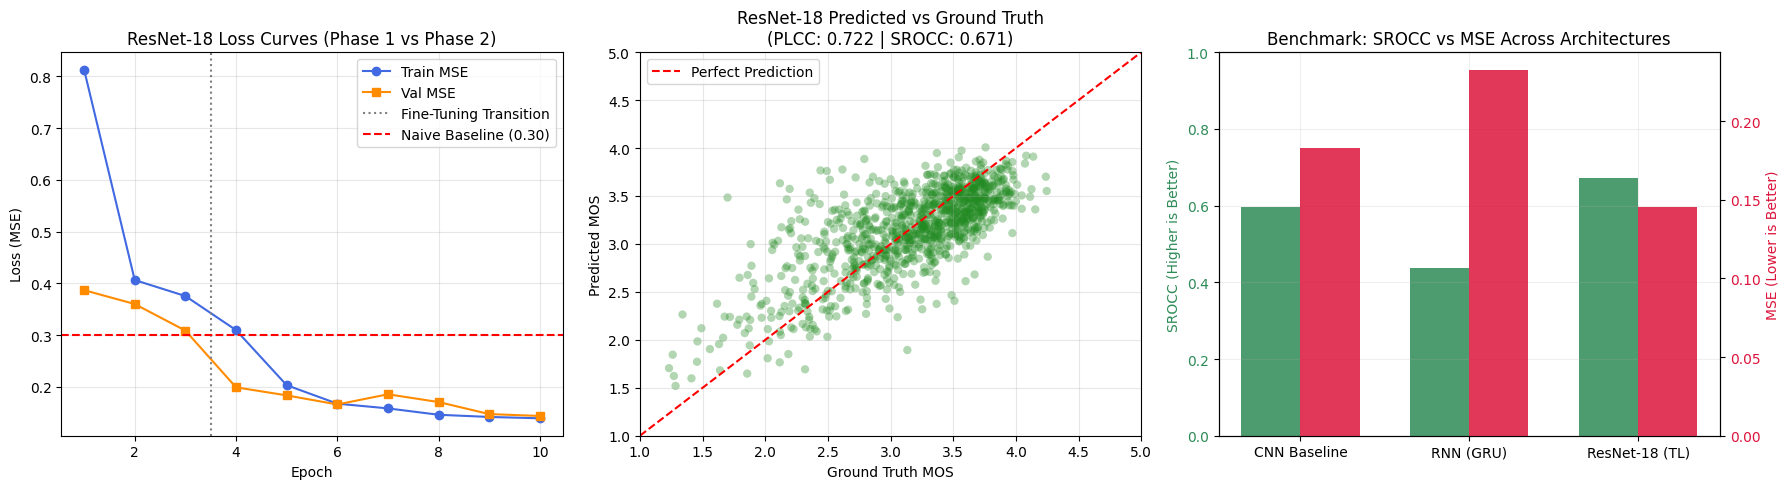

In [21]:
# Visualizations: Learning curves, Predictions vs Ground Truth, and Model Comparison
fig = plt.figure(figsize=(18, 5))

# 1. ResNet-18 Learning Curves with Phase 1 / Phase 2 split
plt.subplot(1, 3, 1)
plt.plot(range(1, num_epochs+1), train_losses_resnet, label='Train MSE', color='royalblue', marker='o')
plt.plot(range(1, num_epochs+1), val_losses_resnet, label='Val MSE', color='darkorange', marker='s')
plt.axvline(x=phase1_epochs + 0.5, color='gray', linestyle=':', label='Fine-Tuning Transition')
plt.axhline(naive_test_mse, color='red', linestyle='--', label=f'Naive Baseline ({naive_test_mse:.2f})')
plt.title('ResNet-18 Loss Curves (Phase 1 vs Phase 2)')
plt.xlabel('Epoch')
plt.ylabel('Loss (MSE)')
plt.legend()
plt.grid(True, alpha=0.3)

# 2. Scatter Plot: Ground Truth vs Predicted MOS
plt.subplot(1, 3, 2)
plt.scatter(resnet_test_targets, resnet_test_predictions, alpha=0.35, color='forestgreen', edgecolors='none')
plt.plot([1, 5], [1, 5], color='red', linestyle='--', label='Perfect Prediction')
plt.title(f'ResNet-18 Predicted vs Ground Truth\n(PLCC: {resnet_plcc:.3f} | SROCC: {resnet_srocc:.3f})')
plt.xlabel('Ground Truth MOS')
plt.ylabel('Predicted MOS')
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.legend()
plt.grid(True, alpha=0.3)

# 3. Bar Chart Comparison across all 3 architectures
plt.subplot(1, 3, 3)
models_names = ['CNN Baseline', 'RNN (GRU)', 'ResNet-18 (TL)']
srocc_values = [
    m1_srocc if not np.isnan(m1_srocc) else 0.0,
    m2_srocc if not np.isnan(m2_srocc) else 0.0,
    resnet_srocc
]
mse_values = [
    m1_mse if not np.isnan(m1_mse) else 0.0,
    m2_mse if not np.isnan(m2_mse) else 0.0,
    resnet_mse
]

x_pos = np.arange(len(models_names))
width = 0.35

ax1 = plt.gca()
bar1 = ax1.bar(x_pos - width/2, srocc_values, width, label='SROCC (Ranking ↑)', color='seagreen', alpha=0.85)
ax1.set_ylabel('SROCC (Higher is Better)', color='seagreen')
ax1.set_ylim(0, 1.0)
ax1.tick_params(axis='y', labelcolor='seagreen')

ax2 = ax1.twinx()
bar2 = ax2.bar(x_pos + width/2, mse_values, width, label='MSE (Error ↓)', color='crimson', alpha=0.85)
ax2.set_ylabel('MSE (Lower is Better)', color='crimson')
ax2.tick_params(axis='y', labelcolor='crimson')

plt.title('Benchmark: SROCC vs MSE Across Architectures')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(models_names)
ax1.grid(True, alpha=0.2)

fig.tight_layout()
plt.show()


### 3.4 In-Depth Analysis, Summary Benchmark & Roadmap for Milestone 4

#### 1. Global Summary Table (Milestones 1 to 3)

| Model / Architecture | Trainable Params | Best Val MSE ($\downarrow$) | Test MSE ($\downarrow$) | vs. Naive ($\Delta\%$) | vs. CNN ($\Delta\%$) | Test RMSE ($\downarrow$) | PLCC ($\uparrow$) | SROCC ($\uparrow$) | Key Takeaway |
| :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :--- |
| **Naive Baseline (Mean)** | $0$ | $0.2995$ | $0.2995$ | $0.0\%$ | $+63.6\%$ | $0.5473$ | $0.0000$ | $0.0000$ | Constant mean predictor ($\bar{y}=3.16$) |
| **M1: CNN Baseline** | $307,329$ | $0.1855$ | $0.1831$ | $-38.9\%$ | $0.0\%$ | $0.4280$ | $0.6283$ | $0.5970$ | Good 2D spatial baseline from scratch |
| **M2: RNN (Bi-GRU)** | $707,713$ | $0.2380$ | $0.2323$ | $-22.4\%$ | $+26.9\%$ | $0.4820$ | $0.4786$ | $0.4376$ | 1D row slicing breaks 2D spatial topology |
| **M3: ResNet-18 (Phase 1: Frozen)** | $65,793$ | $0.3086$ | — | — | — | — | — | — | Semantic ImageNet features ignore blur/noise |
| **M3: ResNet-18 (Phase 2: Fine-Tuned)** | $11,242,305$ | **$0.1435$** | **$0.1454$** | **$-51.5\%$** | **$-20.6\%$** | **$0.3813$** | **$0.7217$** | **$0.6711$** | **Best model: filters adapt to IQA distortions** |

---

#### 2. Key Insights from the Cross-Model Comparison
- **Massive Gain from Fine-Tuning ($\text{MSE}: 0.1831 \to 0.1454$, $\text{PLCC}: 0.6283 \to 0.7217$)**:
  - ResNet-18 reduces test MSE by **$51.5\%$** compared to the Naive Baseline and by **$20.6\%$** compared to our CNN Baseline, while boosting linear correlation (PLCC) by **+$9.3$ points** ($0.6283 \to 0.7217$) and rank correlation (SROCC) by **+$7.4$ points** ($0.5970 \to 0.6711$).
- **Why Phase 1 (Frozen) Stagnated at $0.3086$ While Phase 2 (Unfrozen) Dropped to $0.1435$**:
  - On ImageNet, ResNet is trained to be **distortion-invariant** (a blurry or noisy dog must still be classified as a dog). When the backbone is frozen in Phase 1, its features only describe semantic content, not image quality.
  - Once unfrozen in Phase 2 ($\text{lr}=10^{-4}$), the pre-trained Gabor, edge, and texture filters rapidly specialize in quantifying sharpness, noise, and compression artifacts—cutting validation MSE from $0.3086$ to $0.1989$ in a single epoch and reaching $0.1435$ by Epoch 10.
- **Why the RNN (Milestone 2) Failed ($\text{MSE} = 0.2323$)**:
  - Despite having $2.3\times$ more parameters than the CNN ($707\text{k}$ vs. $307\text{k}$), reading an image as $128$ sequential 1D lines destroys vertical pixel neighborhoods and 2D translation invariance.

---

#### 3. Roadmap & Ingenious Tricks for Milestone 4 ("The Ultimate Model")
Observed limitations in Milestone 3 (such as the validation loss bounce at Epoch 7 from $0.1658 \to 0.1855$, fixed $128 \times 128$ resolution, and uniform learning rate) directly motivate the enhancements we will deploy in **Milestone 4**:

##### A. Core Training & Optimization Pillars
1. **Differential Learning Rates (Layer-wise LR) + `AdamW` with Weight Decay ($10^{-4}$)**:
   - Instead of a single learning rate, apply a **smaller LR ($10^{-4}$)** to the pre-trained ResNet backbone (to gently adapt features without catastrophic forgetting) and a **larger LR ($5 \times 10^{-4}$)** to the regression head, regularized with decoupled weight decay (`AdamW`).
2. **Learning Rate Scheduler (`ReduceLROnPlateau` or `CosineAnnealingLR`)**:
   - Automatically decay the learning rate when validation loss plateaus (or follow a smooth cosine curve down to $10^{-6}$), eliminating late-epoch oscillations and allowing fine-grained convergence.
3. **Early Stopping with Best-Weight Restoration**:
   - Increase the maximum epoch budget (e.g., $15\text{–}20$ epochs) while monitoring validation MSE/SROCC with a `patience` counter to stop automatically once generalization peaks.
4. **Batch Size & Gradient Clipping**:
   - Use a well-balanced batch size ($32$ or $64$) for stable `BatchNorm` statistics, combined with `clip_grad_norm_(max_norm=1.0)` to prevent gradient spikes from outlier images.

##### B. Ingenious IQA-Specific Tricks ("Astuces Ingénieuses")
1. **Quality-Preserving Data Augmentation (`RandomHorizontalFlip` Only)**:
   - *Crucial IQA Insight*: Standard classification augmentations like `ColorJitter`, `GaussianBlur`, or aggressive `RandomResizedCrop` **alter the visual quality of the image** and invalidate its ground-truth MOS! In contrast, a **Horizontal Flip (`p=0.5`)** is 100% quality-preserving (a mirrored image has the exact same sharpness, noise, and aesthetic appeal), effectively doubling training diversity for free.
2. **Higher Resolution ($224 \times 224$) & Native ImageNet Normalization**:
   - Downsampling $512 \times 384$ images to $128 \times 128$ erases high-frequency distortions (subtle blur, sensor grain). Raising input resolution to **$224 \times 224$** (ResNet's native resolution) and using exact **ImageNet normalization** ($\mu=[0.485, 0.456, 0.406], \sigma=[0.229, 0.224, 0.225]$) aligns input statistics with the pre-trained weights and preserves fine visual details.
3. **Dual-Pooling Feature Aggregation (`AvgPool` + `MaxPool` Concatenation)**:
   - While global average pooling captures the *overall average quality* of an image, global max pooling captures the *most severe local artifact or sharpest region*. Concatenating both (`512 + 512 = 1024` features) before the MLP head with `BatchNorm1d`, `GELU/ReLU`, and `Dropout` provides a much richer representation for regression.
4. **Test-Time Augmentation (TTA)**:
   - During final test evaluation, averaging the predicted MOS of each test image and its horizontally flipped counterpart ($\hat{y} = \frac{1}{2}[f(x) + f(\text{flip}(x))]$) reduces prediction variance and boosts test MSE, PLCC, and SROCC at zero training cost.


##Milestone 4
The Ultimate Model: Combine Early Stopping, Schedulers, Regularization, and your best architecture to build your final model.